In [3]:
#Load standard libraries
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
#Read in the data
data = pd.read_csv("EURUSD Mean Reverting.csv")

In [13]:
#View the data
data

,Time,Open,High,Low,Close
3650,2011.02.08 00:00:00,1.35802,1.36871,1.35720,1.36277
3651,2011.02.09 00:00:00,1.36235,1.37424,1.36106,1.37237
3652,2011.02.10 00:00:00,1.37239,1.37272,1.35773,1.35936
3653,2011.02.11 00:00:00,1.35928,1.36204,1.34972,1.35513
3654,2011.02.14 00:00:00,1.35240,1.35579,1.34279,1.34885
...,...,...,...,...,...
5835,2019.07.09 00:00:00,1.12141,1.12187,1.11932,1.12078
5836,2019.07.10 00:00:00,1.12076,1.12642,1.12018,1.12503
5837,2019.07.11 00:00:00,1.12503,1.12857,1.12451,1.12532
5838,2019.07.12 00:00:00,1.12532,1.12748,1.12383,1.12699


In [16]:
#Generate a target that is a ratio of the data
data["Target"] =  data["Close"] / data["Open"]

/tmp/ipykernel_2854/1393420122.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["Target"] =  data["Close"] / data["Open"]


In [17]:
data

,Time,Open,High,Low,Close,Target
3650,2011.02.08 00:00:00,1.35802,1.36871,1.35720,1.36277,1.003498
3651,2011.02.09 00:00:00,1.36235,1.37424,1.36106,1.37237,1.007355
3652,2011.02.10 00:00:00,1.37239,1.37272,1.35773,1.35936,0.990506
3653,2011.02.11 00:00:00,1.35928,1.36204,1.34972,1.35513,0.996947
3654,2011.02.14 00:00:00,1.35240,1.35579,1.34279,1.34885,0.997375
...,...,...,...,...,...,...
5835,2019.07.09 00:00:00,1.12141,1.12187,1.11932,1.12078,0.999438
5836,2019.07.10 00:00:00,1.12076,1.12642,1.12018,1.12503,1.003810
5837,2019.07.11 00:00:00,1.12503,1.12857,1.12451,1.12532,1.000258
5838,2019.07.12 00:00:00,1.12532,1.12748,1.12383,1.12699,1.001484


In [18]:
#Set the forecast horizon
HORIZON = 10

In [19]:
#Shift the target
data["Target"] = data["Target"].shift(-10)

/tmp/ipykernel_2854/3214733939.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data["Target"] = data["Target"].shift(-10)


In [21]:
data.dropna(inplace=True)
data

/tmp/ipykernel_2854/731352529.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data.dropna(inplace=True)


,Time,Open,High,Low,Close,Target
3650,2011.02.08 00:00:00,1.35802,1.36871,1.35720,1.36277,0.998552
3651,2011.02.09 00:00:00,1.36235,1.37424,1.36106,1.37237,1.006950
3652,2011.02.10 00:00:00,1.37239,1.37272,1.35773,1.35936,1.003804
3653,2011.02.11 00:00:00,1.35928,1.36204,1.34972,1.35513,0.996450
3654,2011.02.14 00:00:00,1.35240,1.35579,1.34279,1.34885,1.004496
...,...,...,...,...,...,...
5825,2019.06.25 00:00:00,1.13979,1.14116,1.13437,1.13655,0.999438
5826,2019.06.26 00:00:00,1.13665,1.13909,1.13470,1.13683,1.003810
5827,2019.06.27 00:00:00,1.13684,1.13811,1.13474,1.13689,1.000258
5828,2019.06.28 00:00:00,1.13688,1.13931,1.13501,1.13693,1.001484


Text(0.5, 1.0, 'Distribution Of The Target')

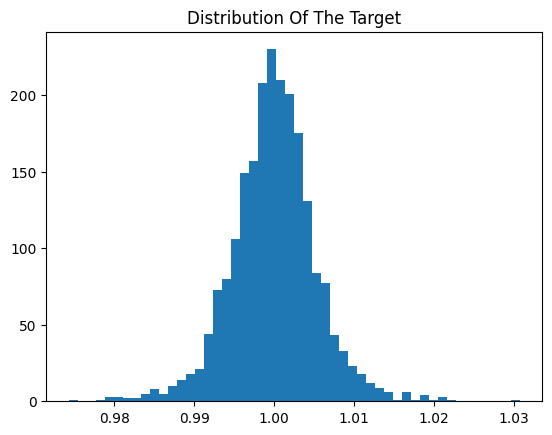

In [28]:
plt.hist(data['Target'],bins=50)
plt.title("Distribution Of The Target")

In [32]:
#Train test split
train , test = data.iloc[0:data.shape[0]//2,:] , data.iloc[data.shape[0]//2:,:]

In [33]:
train

,Time,Open,High,Low,Close,Target
3650,2011.02.08 00:00:00,1.35802,1.36871,1.35720,1.36277,0.998552
3651,2011.02.09 00:00:00,1.36235,1.37424,1.36106,1.37237,1.006950
3652,2011.02.10 00:00:00,1.37239,1.37272,1.35773,1.35936,1.003804
3653,2011.02.11 00:00:00,1.35928,1.36204,1.34972,1.35513,0.996450
3654,2011.02.14 00:00:00,1.35240,1.35579,1.34279,1.34885,1.004496
...,...,...,...,...,...,...
4735,2015.04.13 00:00:00,1.06030,1.06190,1.05202,1.05659,1.002228
4736,2015.04.14 00:00:00,1.05658,1.07043,1.05311,1.06539,1.008182
4737,2015.04.15 00:00:00,1.06534,1.07015,1.05705,1.06869,1.013647
4738,2015.04.16 00:00:00,1.06869,1.08172,1.06246,1.07592,1.008492


In [40]:
#Import statistical models
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.ensemble import RandomForestRegressor,GradientBoostingRegressor
from sklearn.svm import LinearSVR
from sklearn.metrics import root_mean_squared_error as RMSE

In [37]:
#Set performance benchmarks
train_benchmark = train['Target'].std()
test_benchmark = test['Target'].std()

In [38]:
#Evaluate the models
models = [LinearRegression(),Ridge(),Lasso(),RandomForestRegressor(),GradientBoostingRegressor(),LinearSVR()]

In [41]:
train_error = []
test_error = []

In [43]:
for model in models:
  #Fit the model on the training set
  model.fit(train.loc[:,['Open','High','Low','Close']],train['Target'])
  #Evaluate the model
  train_error.append(RMSE(train['Target'],model.predict(train.loc[:,['Open','High','Low','Close']])))
  test_error.append(RMSE(test['Target'],model.predict(test.loc[:,['Open','High','Low','Close']])))

/usr/local/lib/python3.12/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


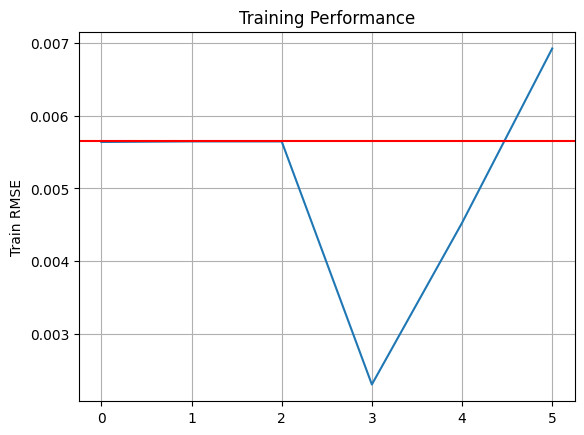

In [47]:
plt.plot(train_error)
plt.grid()
plt.title('Training Performance')
plt.ylabel('Train RMSE')
plt.axhline(train_benchmark,color='red')

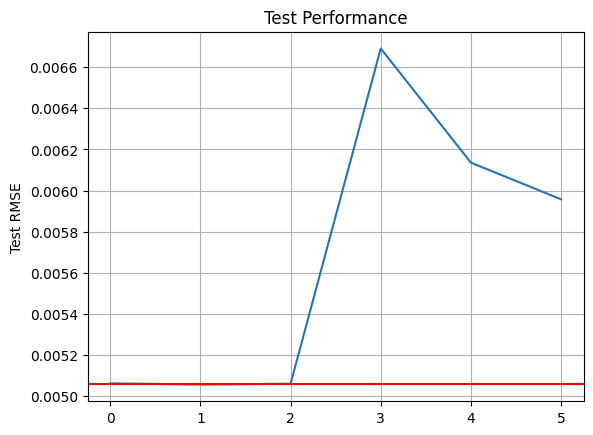

In [50]:
plt.plot(test_error)
plt.grid()
plt.title('Test Performance')
plt.ylabel('Test RMSE')
plt.axhline(test_benchmark,color='red')

In [55]:
import onnx
from skl2onnx.common.data_types import FloatTensorType
from skl2onnx import convert_sklearn

In [56]:
initial_types = [('float_input',FloatTensorType([1,4]))]

In [57]:
final_types = [('float_output',FloatTensorType([1,1]))]

In [58]:
model = LinearRegression()

model.fit(data.loc[:,['Open','High','Low','Close']],data.loc[:,'Target'])

LinearRegression()

In [59]:
onnx_proto = convert_sklearn(model,initial_types=initial_types,final_types=final_types,target_opset=12)

In [60]:
onnx.save(onnx_proto,'EURUSD Linear Regressor.onnx')